***una porbabilidad de dos maneras: contar y simular***

In [ ]:
import numpy as np
import itertools

itertools es la herramienta para hacer iteraciones, en si es eso. Herramientas de iteracion

In [ ]:
pares = list(itertools.product(range(1,7), repeat=2))
favorables = [i for i in pares if 6 in i]
valor_exacto = len(favorables) / len(pares)

print("total de pares:", len(pares))
print("pares con al menos un 6:", len(favorables))
print("valor exacto:", valor_exacto)

total de pares: 36
pares con al menos un 6: 11
valor exacto: 0.3055555555555556


con pares hacemos que en una lsita agregue las tiradas de dos dados, favorables agarra esa lista y extrae unicamente a los que tengan 6, luego con len vemos la cantidad que tiene las listas y en valor_exacto los guardamos como favorables/pares. asi obtenemos el valor exacto de la probabilidad

In [ ]:
rng = np.random.default_rng(42)

print("n\testimacion\terror absoluto")
for n in [100, 1000, 100000]:
    tiradas = rng.integers(1, 7, size=(n, 2))
    tiene_seis = np.any(tiradas == 6, axis=1)
    estimacion = np.mean(tiene_seis)
    error = abs(estimacion - valor_exacto)
    print(f"{n}\t{estimacion:.5f}\t\t{error:.5f}")

n	estimacion	error absoluto
100	0.24000		0.06556
1000	0.31000		0.00444
100000	0.30583		0.00027


rng guarda la configuracion del random, en este caso la semilla sera 42, print hace que se muestre las columnas de nuestra tabla que formaremos con for, n recorre el array para cada valor que contiene, dentro las tiradas con rng se hacen en 100, 1000, etc. de esas tiradas lo que nos sirve es si tiene seis, entonces para eso np.any hace que si en tiradas hay por lo menos un seis y axis hace que vaya tupla por tupla, la estimacion es el promedio de esa variable que contiene los seis almacenados "tiene_seis", finalmente error absoluto es ejecutar la formula para que nos muestre que tanto difiere. mostramos los n que fueron operados, estimulacion y error con .5 decimales

**cual se acerco mas y porque?**<br>
el que se acerco mas es 100_000 porque hay mas intentos de tiradas, mientras mas sean estos intentos mas va a converger al valor exacto<br>
**que pasa a la estimacion cuando tienes pocas tiradas**<br>
hay mas fluctuacion en menos intentos, como en la suerte, los resultados pueden alejarse mucho o poco de la realidad

***perfil estadistico por especie y limpieza de datos***

In [ ]:
import pandas as pd
from sklearn.datasets import load_iris

cargamos pandas y el dataset iris

In [ ]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)
columnas = iris.feature_names

en iris guardamos los datos, df contiene los datos con las columnas creadas por defecto, df['especies'] hace una nueva columna, con categorical cargamos iris target y lo traducimos de numeros a strings, columnas contiene iris.feature_names para no ir escribiendo cada vez todo el texto largo

In [ ]:
#1 perfil por especie
perfil = df.groupby('species')[columnas].describe() #!=agg()
display(perfil.round(2))  

sepal length (cm)                                        \
                       count  mean   std  min   25%  50%  75%  max   
species                                                              
setosa                  50.0  5.01  0.35  4.3  4.80  5.0  5.2  5.8   
versicolor              50.0  5.94  0.52  4.9  5.60  5.9  6.3  7.0   
virginica               50.0  6.59  0.64  4.9  6.22  6.5  6.9  7.9   

           sepal width (cm)        ... petal length (cm)       \
                      count  mean  ...               75%  max   
species                            ...                          
setosa                 50.0  3.43  ...              1.58  1.9   
versicolor             50.0  2.77  ...              4.60  5.1   
virginica              50.0  2.97  ...              5.88  6.9   

           petal width (cm)                                       
                      count  mean   std  min  25%  50%  75%  max  
species                                                           
setosa                 50.0  0.25  0.11  0.1  0.2  0.2  0.3  0.6  
versicolor             50.0  1.33  0.20  1.0  1.2  1.3  1.5  1.8  
virginica              50.0  2.03  0.27  1.4  1.8  2.0  2.3  2.5  

[3 rows x 32 columns]

perfil es la tabla donde vemos los estadisticos, primero debemos agruparlos por especies, luego trabajar con "columnas"=iris.feature_names trabajando con .describe() que es la forma mas directa de obtener de una los estadisticos mas usados. seria tambien con .agg() pero por comodidad elegi .describe(). Display para que vemos mejor los datos obtenidos

In [ ]:
#2 faltantes
rng = np.random.default_rng(7)
for _ in range(10):
    fila = rng.integers(0, len(df))
    col = rng.choice(columnas)
    df.loc[fila, col] = np.nan

print(df[columnas].isna().sum())

df[columnas] = df.groupby('species')[columnas].transform(lambda x: x.fillna(x.median()))#median porq != mean
print(df[columnas].isna().sum())

#3 lectura
print(df.groupby('species')[columnas].mean().round(2))

sepal length (cm)    2
sepal width (cm)     2
petal length (cm)    1
petal width (cm)     5
dtype: int64
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64
            sepal length (cm)  sepal width (cm)  petal length (cm)  \
species                                                              
setosa                   5.01              3.44               1.46   
versicolor               5.94              2.77               4.26   
virginica                6.58              2.97               5.56   

            petal width (cm)  
species                       
setosa                  0.24  
versicolor              1.32  
virginica               2.02  


rng reinicia la semilla en 7. el bucle se repite 10 veces; usamos _ porque no necesitamos el indice, solo realizar las repeticiones. fila genera un entero aleatorio dentro del rango de la cantidad de filas del df, y col hace lo mismo pero eligiendo una columna de la lista de columnas. luego, con df.loc, cambiamos el valor ubicado en esas coordenadas por un np.nan; como son datos numericos, no hay problema en usar np.nan.

a continuacion, imprimimos la cantidad de nulos en las columnas con isna().sum(). despues, en df[columnas], agrupamos por especies para rellenar los nulos usando .transform() con la mediana (usamos median y no mean porque es mas robusta). volvemos a mostrar la suma de nulos para verificar que ya no quedan valores faltantes. finalmente, mostramos las medias de las columnas con .mean() agrupadas por especie, aplicando .round(2) para redondear el resultado a dos decimales.

**porque una caracteristica con medias muy distintas entre especies separa nejor que una con medias parecidas**<br>
porque si los promedios (medias) son muy distintos entre especies, hay menos solapamiento o mezcla entre sus datos. esto hace que los grupos esten mas separados y sea mas facil para un algoritmo trazar una linea clara para distinguirlos. en cambio, si las medias son parecidas, los datos se enciman y se prestan a confusion al intentar clasificarlos.

***formas de comparar tres flores***

In [ ]:
#1 funciones
def distancia_euclidiana(a,b):
    return np.sqrt(np.sum((a-b)**2))

def producto_punto(a,b):
    return np.sum(a*b)

def similitud_coseno(a,b):
    return np.dot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b))

introducimos las funciones, euclidiana para ver la distancia entre dos puntos (0 identicos). prodPunto para ver la direccion y el tamanio de los vectores y coseno para ver el angulo y direccion (1 apuntan al mismo lado, 0 diferente, -1 opuesto).

In [ ]:
#2 elegir 4 flores: dos iguales, dos de especies distintas
iris = load_iris()
X = iris.data
y = iris.target

uno, dos = 0, 1 #setosas
unoOO, tres = 0, 100 #setosa - virginica

pares = {
    f"{uno} y {dos} (setosas)": (X[uno], X[dos]),
    f"{unoOO} y {tres} (setosa/virginica)": (X[unoOO], X[tres]),
}

cargamos iris nuevamente, almacenamos en X y en "y" seria las etiquetas que identifican cada flor, asignamos en uno, dos.. los vectores a operar. pares guarda un dos pares de muestras de flores con sus datos en un diccionario que lo vamos a usar abajo.

In [ ]:
#3 tabla de resultados
print(f"{'par':30} {'euclidiana':>12} {'punto':>12} {'coseno':>12}")
for nombre, (a,b) in pares.items():
    d = distancia_euclidiana(a,b)
    p = producto_punto(a,b)
    c = similitud_coseno(a,b)
    print(f"{nombre:30} {d:12.4f} {p:12.4f} {c:12.4f}")

par                              euclidiana        punto       coseno
0 y 1 (setosas)                      0.5385      37.4900       0.9986
0 y 100 (setosa/virginica)           5.2849      52.5800       0.8601


imprimimos los nombres de las columnas, :30 y >12 hacen que se reserve espacio; en el bucle tenemos nombre, (a,b) para que vaya obteniendo de pares.items() los valores que estaban en pares de la anterior ejecucion, d, p y c son las funciones que habiamos definido arriba, imprimimos nombre que es el de pares y luego hace los calculos llamando a las funciones, imprimiendo cada resultado con 4 decimales.

**las flores de la misma especie salieron "mas parecidas" (menor distancia, mayor coseno)?**<br>
si, las flores 0-1 setosas son las mas parecidas porque comparten la especie, por lo tanto los numeros varian muy poco.<br>
**la distancia euclidiana y la similitud coseno ordenan las flores igual?**<br>
no, mientras la distancia euclidiana mide la diferencia directa entre los valores, la similitud de coseno se fija en la proporcion u orientacion de las caracteristicas.

***bajar la colina: descenso de gradiente***

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
def derivada(x):
    return 2 * (x - 4)

#1 descenso de gradiente
def descenso(tasa, pasos=30, x0=10):
    x = x0
    trayectoria = [x]
    for _ in range(pasos):
        x = x - tasa * derivada(x)
        trayectoria.append(x)
    return trayectoria

derivada calcula la pendiente de la funcion en un punto para saber donde moverse, en la funcion descenso hacemos prumero actualizar el valor de x pasandole la tasa multiplicada por la derivada para acercarse al minimo, guardando cada paso en una lista -> trayectoria

Text(0.5, 1.0, 'descenso de gradiente')

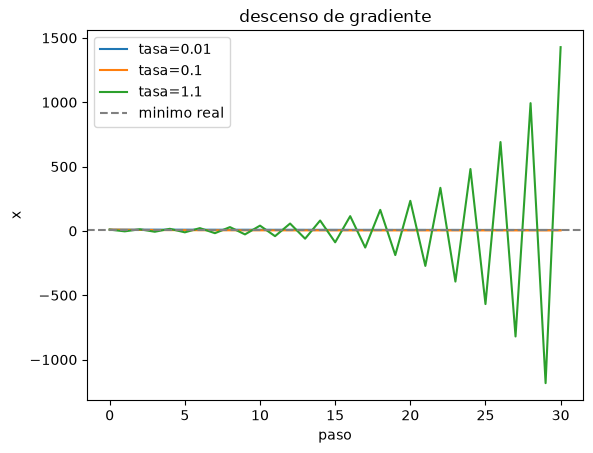

In [ ]:
#2 res tasas de aprendizaje
tasas = [0.01, 0.1, 1.1]
resultados = {t: descenso(t) for t in tasas}

for t, trayectoria in resultados.items():
    plt.plot(trayectoria, label=f"tasa={t}")

plt.axhline(4, color='gray', linestyle='--', label='minimo real')
plt.xlabel('paso')
plt.ylabel('x')
plt.legend()
plt.title('descenso de gradiente')

en tasas[] asignamos la lista de numeros, en resultados vemos el descenso con cada tasa guardando las trayectorias de como se mueve en x en cada paso, graficamos para cada tasa si converge o no hacia el objetivo, eso lo vemos con plt.plot. 
plt.axhline hace que veamos la linea horixontal, los x, ylabel muestran los titulos en ordenada / absisa.
legend() muestra el caudro con etiquetas de las lineas de tasasm lineas de referencia. 
tittle = titulo

In [ ]:
# 3. comparacion final
print(f"{'tasa':>6} {'x final':>10}")
for t, trayectoria in resultados.items():
    print(f"{t:6.2f} {trayectoria[-1]:10.3f}")

  tasa    x final
  0.01      7.273
  0.10      4.007
  1.10   1428.258


imprimimos las columnas con tasa y x_final, hacemos el bucle que recorre cada tasa y extrae el ultimo valor de sus listas, trayectoria[-1], que seria el punto donde lelgo x despues de los 30 pasos
imprimimos con el miso formato que en el nombre de las columnas

**todas llegan cerca del minimo?**<br>
no, no todas llegan. Solo la tasa de 0.1 se acerca con exito al minimo. La pequenia (0.01) se queda muy corta porque avanza demasiado lento, y la grande (1.1) se pasa de largo, oscila y se dispara
**que pasa con la tasa muy pequenia (avanmza lento?) y con la muy grande (se pasa, oscila o se dispara?)**<br>
+ tasa muy pequenia (0.01) = avanza muy lento aunque vaya en direccion correcta, los pasos son muy pequenios 
+ tasa muy grande (1,1) = es muy agresiva, en lugar de acercarse se pasal oscila violentamenteo se dispara 
